# Damage study: does the detector notice when synthetic data gets worse?

**Question.** If a metric is ever to tell us "this synthetic data is good", there must first be something for it to predict: a detector trained on worse synthetic data must do worse on *real* test data. If it doesn't, no metric can be checked against it.

**How.**
1. Take 200 sequences from the simulator (clean).
2. Make worse versions of the *same* 200 scenes: one defect at a time, at 2–3 strengths.
3. Train the detector on each version, and test every detector on the same real test set.
4. Two settings: **only** (synthetic alone) and **mix** (each batch is half 50 real sequences, half the version).
5. 3 seeds each, so we know how much the score moves just by chance ("seed noise").

**Pass rule (fixed before the runs).** The best-to-worst gap must be at least 3× the seed noise, *and* at least 3 of the 5 defect families must get steadily worse as the damage grows.

Notes: docs/notes/2026-10-28-damage-spread-fair.md.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)

from src.plots import (print_verdict, show_detections, show_family, show_real_and_sim,
                            show_results, show_sequence)

## 1. CARRADA: what the detector trains on

- Each panel is one range-Doppler frame: y = distance from the radar, x = radial speed (Doppler bin; 32 = standing still).
- **Red circles = labels** (where the training says "there is an object").
- The bright vertical line at Doppler 32 is everything static (ground, poles). The radar does not move, so the static world sits only on that one column.
- Top: real CARRADA. Bottom: the clean simulator.

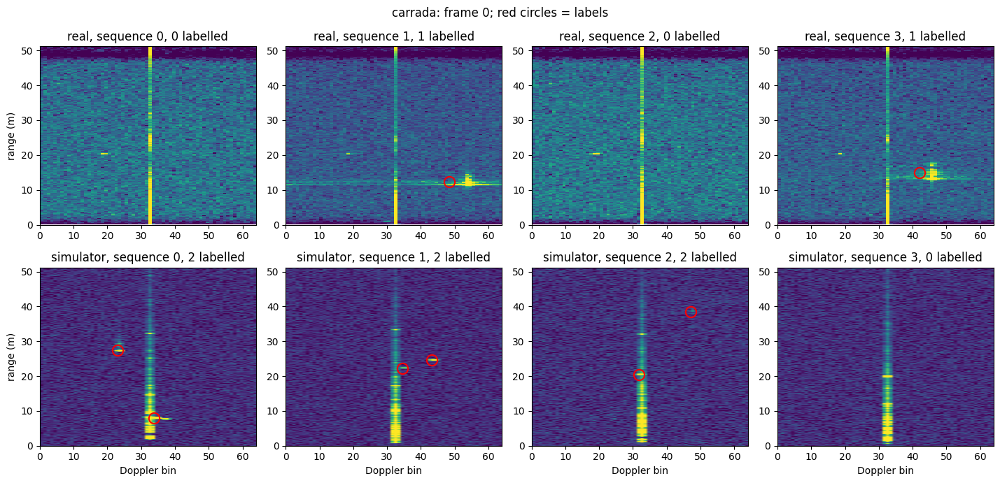

In [2]:
show_real_and_sim("carrada", seqs=(0, 1, 2, 3))

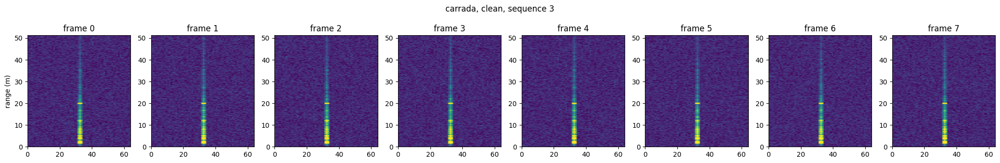

In [3]:
show_sequence("carrada", "clean", seq=3)

## 2. CARRADA: the defects

Each figure shows the **same scene**. The first column is clean; the others are the same scene, damaged more and more.
- Top row: the map, on the clean map's colour scale, with the labels the detector is trained with.
- Bottom row: damaged minus clean, in dB. Red = more power, blue = less, white = unchanged.

**Contrast:** moving objects made 6 / 12 / 20 dB weaker. Labels stay. Look at the blue spots at the objects.

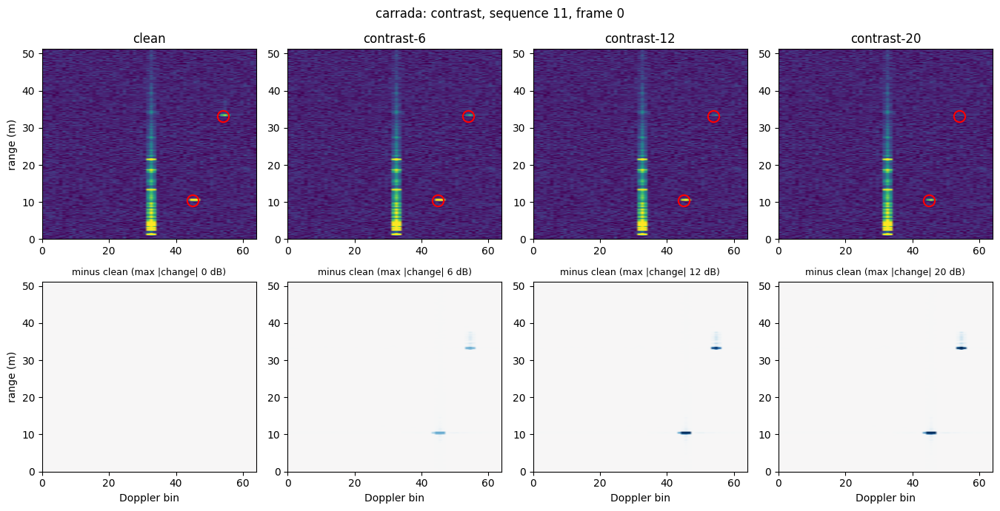

In [4]:
show_family("carrada", "contrast")

**Unrendered:** 10 / 25 / 50% of the (object, frame) pairs are removed from the map, but **the label stays**. The detector is told "there is an object here" over empty background.

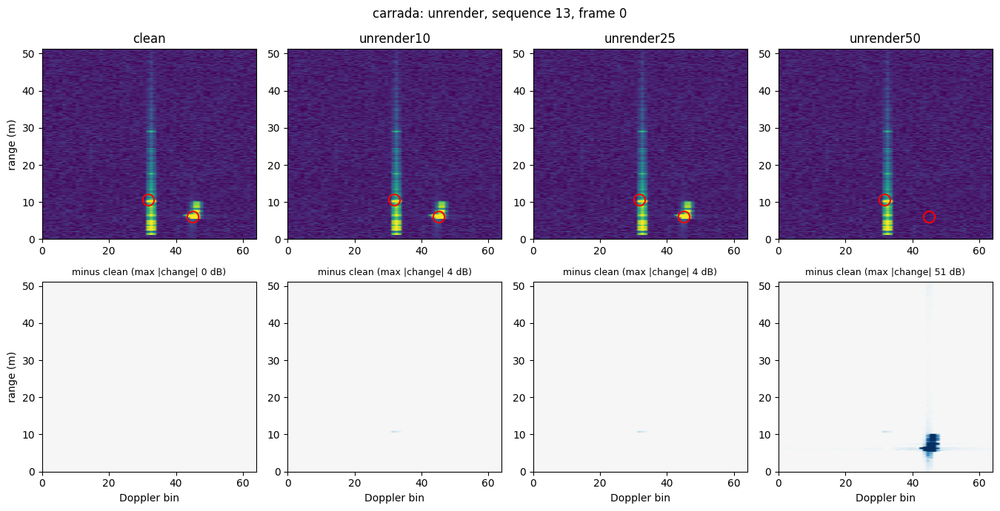

In [5]:
show_family("carrada", "unrender")

**Extra:** in 10 / 25 / 50% of sequences an extra moving object appears in the map, **with no label**. The detector is told "nothing here" over a real-looking object. (The picked sequence is one where the extra object occurs; red in the bottom row is the object. The levels are nested: a sequence that gets an object at 10% also gets it at 25% and 50%, which is why all three columns look the same here. Higher levels just affect more sequences.)

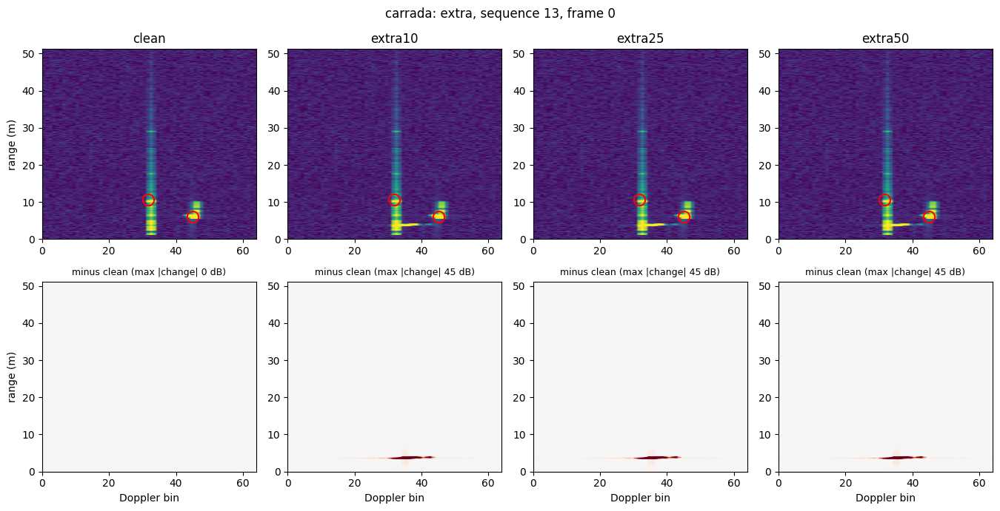

In [6]:
show_family("carrada", "extra")

**Smoothing:** every cell is pulled 25 / 50 / 75% towards the average of its 4 neighbours, except a small box around each label. This copies what our generator does (it makes the speckle texture too smooth; the RADIal DiT was about 36% too smooth, roughly the 25% level).

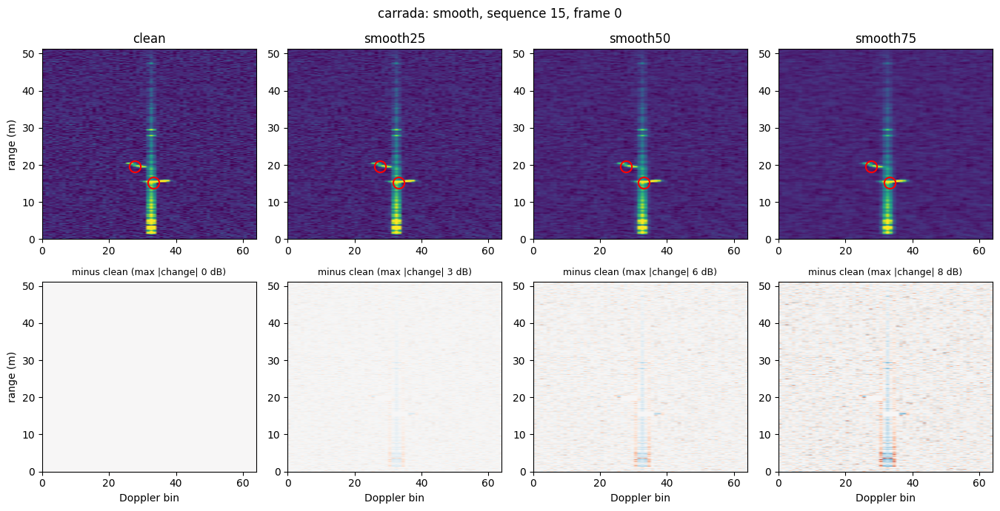

In [7]:
show_family("carrada", "smooth")

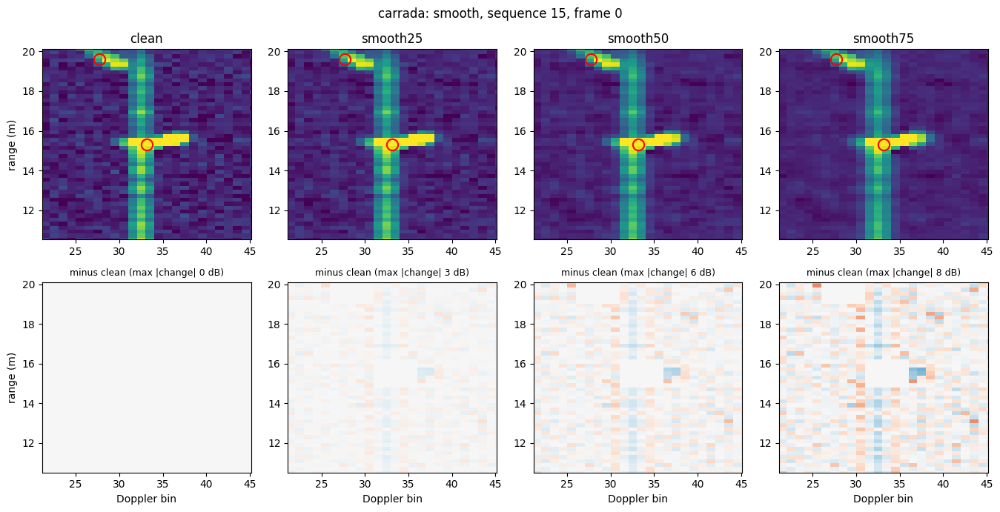

In [8]:
show_family("carrada", "smooth", zoom=24)

Look at the bottom row: around each label there is a small white (unchanged) box, while everything else is smoothed. So in the damaged data, **the only rough-textured patches are exactly where the labels are**. The detector can learn "rough patch = object", and real maps are rough everywhere. This is stronger than what our generator does (it smooths the objects too), so the smoothing result may overstate how much the generator's real defect costs.

**Noise:** the receiver is made 6 / 12 dB noisier, so everything sinks into the noise.

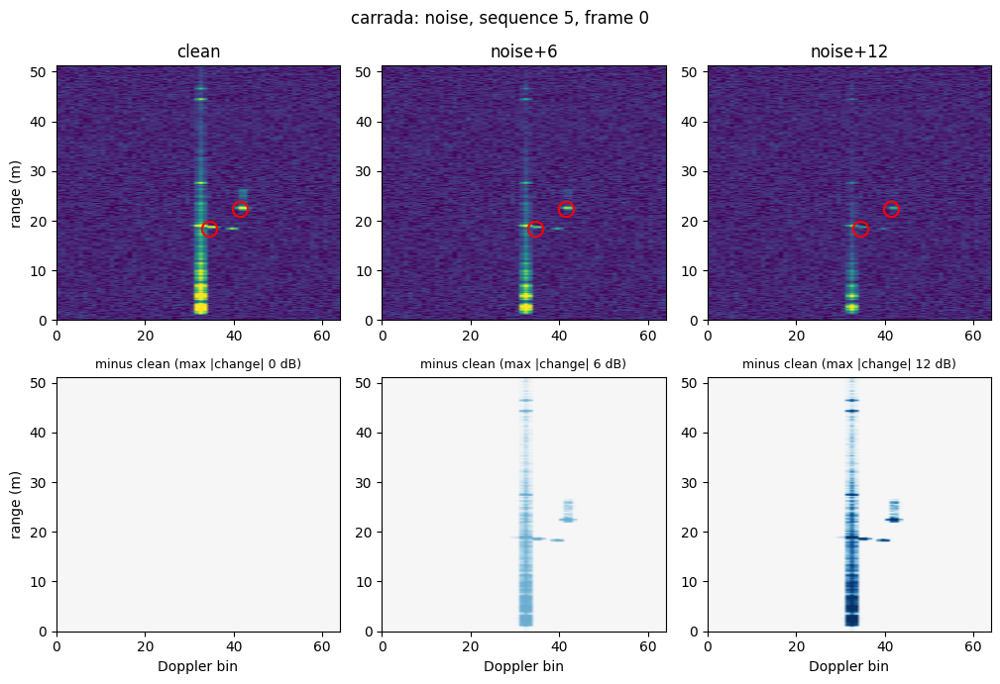

In [9]:
show_family("carrada", "noise")

**Clutter** (reported only, not counted): ground and poles ±6 / ±12 dB. On CARRADA this changes only the zero-Doppler column, away from the moving objects.

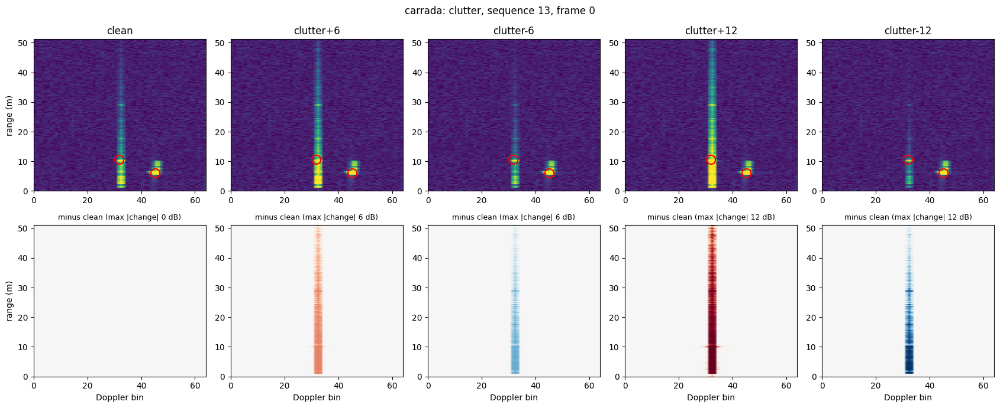

In [10]:
show_family("carrada", "clutter")

**Range shift** (control): the map is untouched and every label is moved 1 / 2 cells further away. The detector learns to point next to the object. This is a known-bad defect, used to check the study can see damage at all.

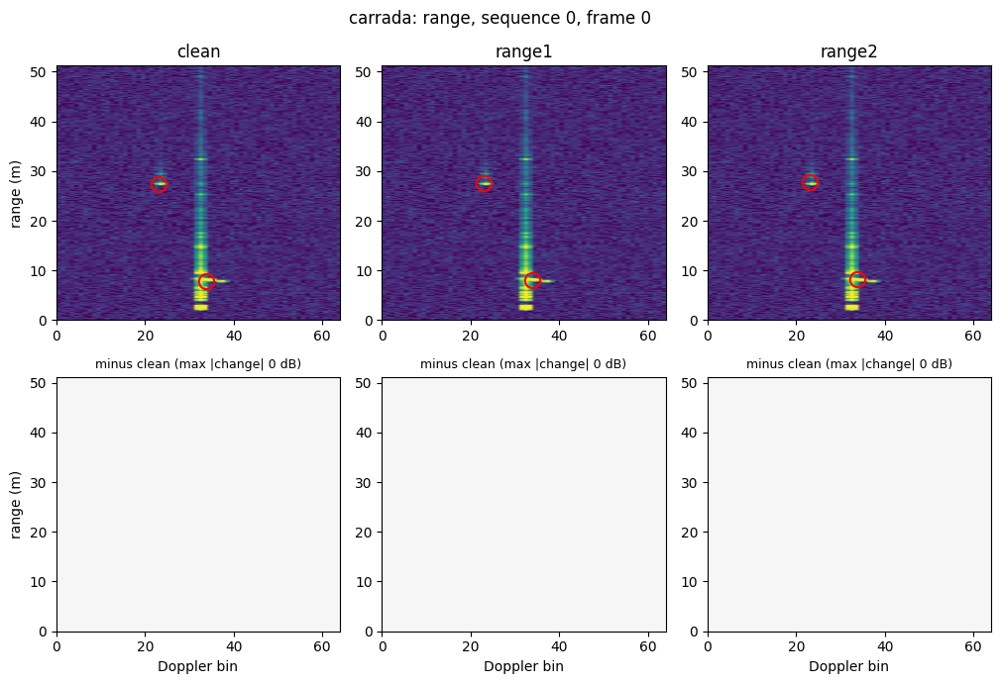

In [11]:
show_family("carrada", "range")

## 3. CARRADA: results

Three scores on the real test set. All compare detections to real labels:
- **ap2** (main): AP, where a detection counts only if it lands within 2 cells of a real object. Strict about position.
- **ap4**: the same, within 4 cells. Forgives small misplacement.
- **recall2**: the share of real objects found within 2 cells. Ignores false alarms.

How to read the plots: one panel per defect family, with the damage growing to the right. Dots = 3 seeds, line = their mean, grey band = clean ± seed noise. A family "responds" if its line leaves the grey band downwards.

In [12]:
print_verdict("carrada")

score    setting    gap  noise gap/noise  ordered families      pass
ap2      only     0.371  0.054       6.9  2/5 extra,smooth     False
ap2      mix      0.060  0.044       1.4  0/5                  False
ap4      only     0.574  0.077       7.4  3/5 contrast,extra,smooth True
ap4      mix      0.089  0.057       1.6  0/5                  False
recall2  only     0.602  0.058      10.4  1/5 smooth           False
recall2  mix      0.057  0.034       1.6  2/5 contrast,noise   False


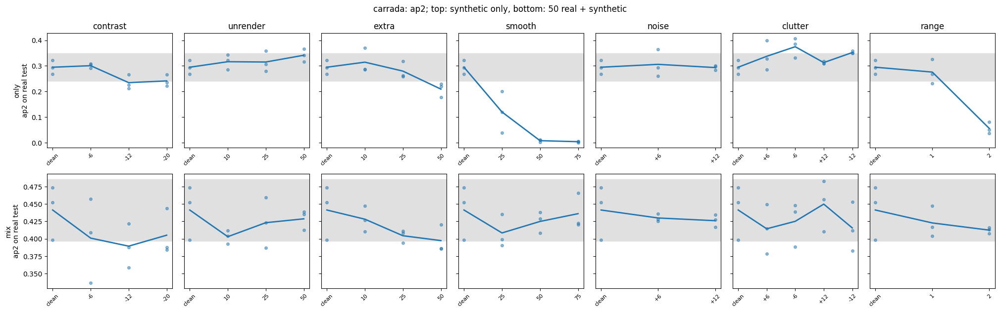

In [13]:
show_results("carrada", "ap2")

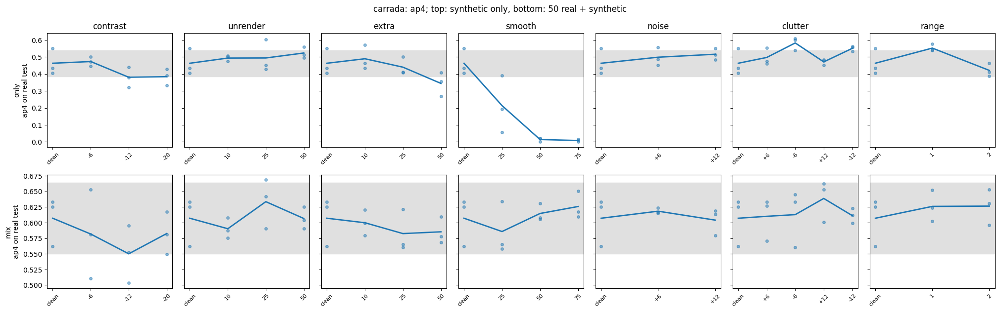

In [14]:
show_results("carrada", "ap4")

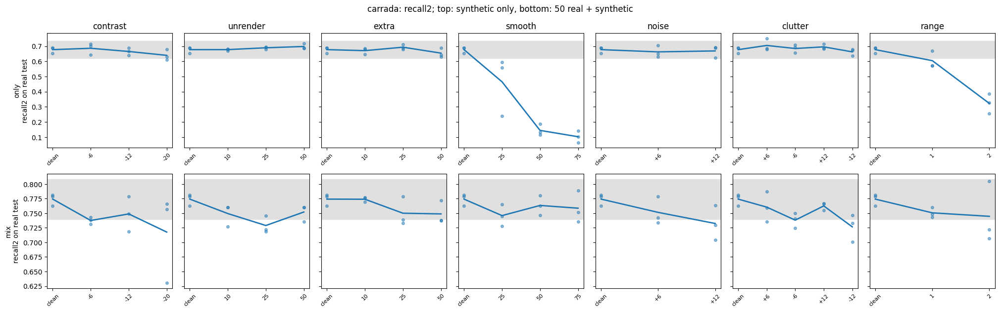

In [15]:
show_results("carrada", "recall2")

**In plain words (top rows, synthetic only):**
- **Smoothing destroys the detector.** At 25% the score halves, and at 50% the detector finds almost nothing. It learned that objects are "the only textured spot", and real maps are textured everywhere.
- **Unlabelled extra objects hurt gradually**, as expected: the detector learns to ignore real-looking objects.
- **Weaker targets hurt a little** (ap4 sees it more clearly than ap2).
- **Unrendered targets and more noise do nothing.** Labels over empty background seem not to mislead it, maybe because such frames carry no strong signal either way.
- Clutter does nothing, as expected on CARRADA.
- Strict verdict: ap2 has 2/5 families ordered (needs 3), so **fail**; ap4 has 3/5, so **pass**.

**Bottom rows (mix, 50 real + synthetic):** everything is flat inside the grey band. With 50 real sequences in every batch, the detector learns from the real half. Even 75% smoothing, which alone gives a useless detector, costs nothing measurable.

## 4. CARRADA: what the trained detectors see on a real test frame

Red circles = real labels; white crosses = detections (score shown). Each panel is the same real frame, scored by a detector trained on a different version (synthetic only, seed 1).

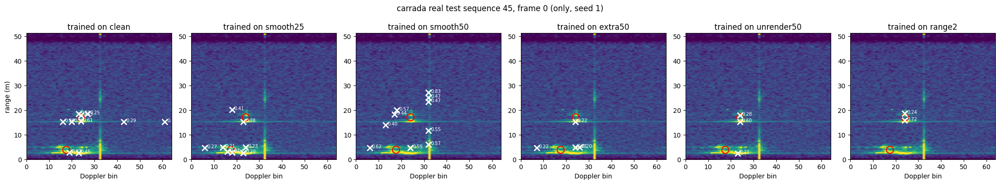

In [16]:
show_detections("carrada", ["clean", "smooth25", "smooth50", "extra50", "unrender50", "range2"])

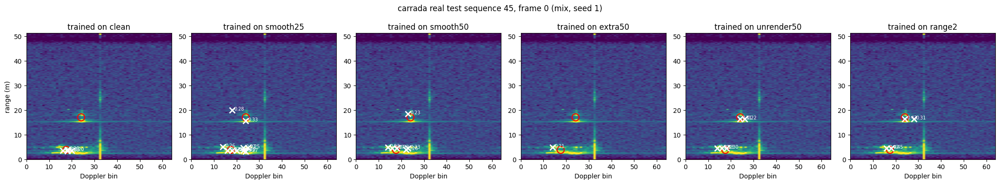

In [17]:
show_detections("carrada", ["clean", "smooth25", "smooth50", "extra50", "unrender50", "range2"], setting="mix")

## 5. RADIal

The same defects on the RADIal simulator. The ego car moves, so the static world spreads over many Doppler bins, and clutter now sits among the vehicles. Maps are 512 range × 256 Doppler. The copies at regular Doppler spacing are DDMA (12 transmitters, each with its own Doppler code). The family figures are zoomed around a labelled vehicle.

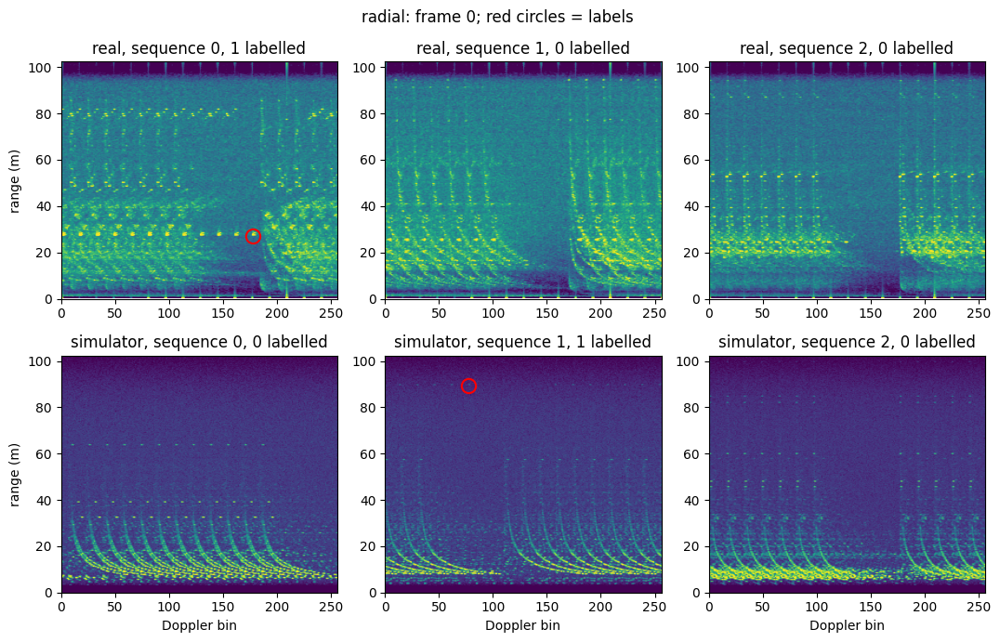

In [18]:
show_real_and_sim("radial", seqs=(0, 1, 2))

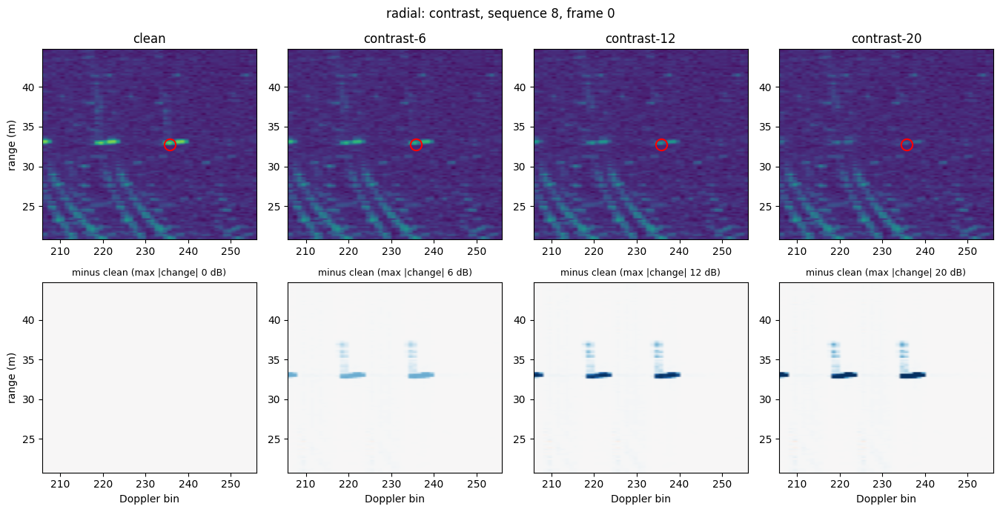

In [19]:
show_family("radial", "contrast", zoom=60)

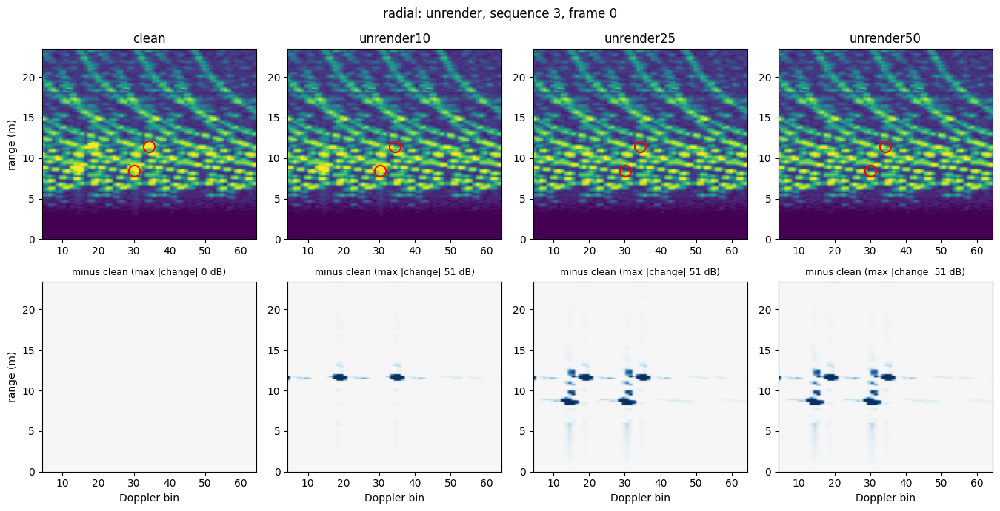

In [20]:
show_family("radial", "unrender", zoom=60)

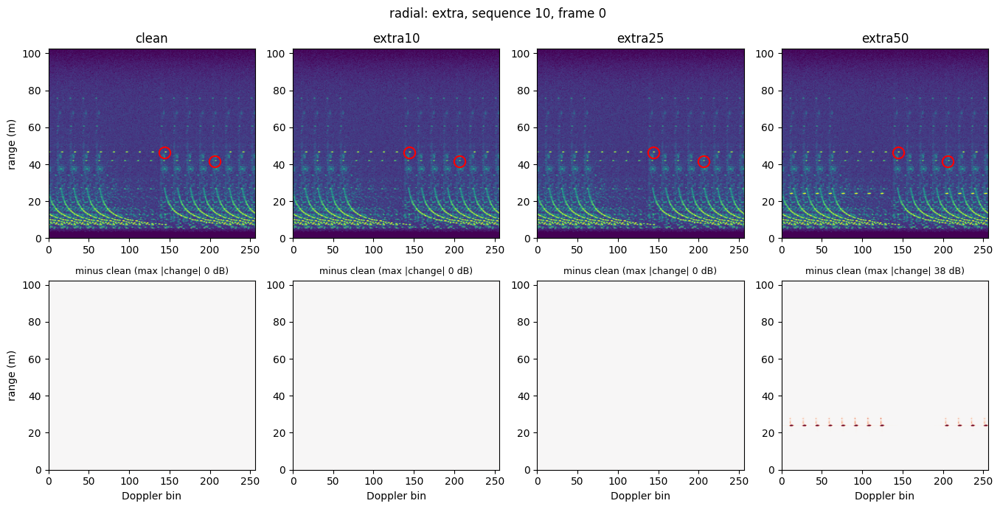

In [21]:
show_family("radial", "extra")

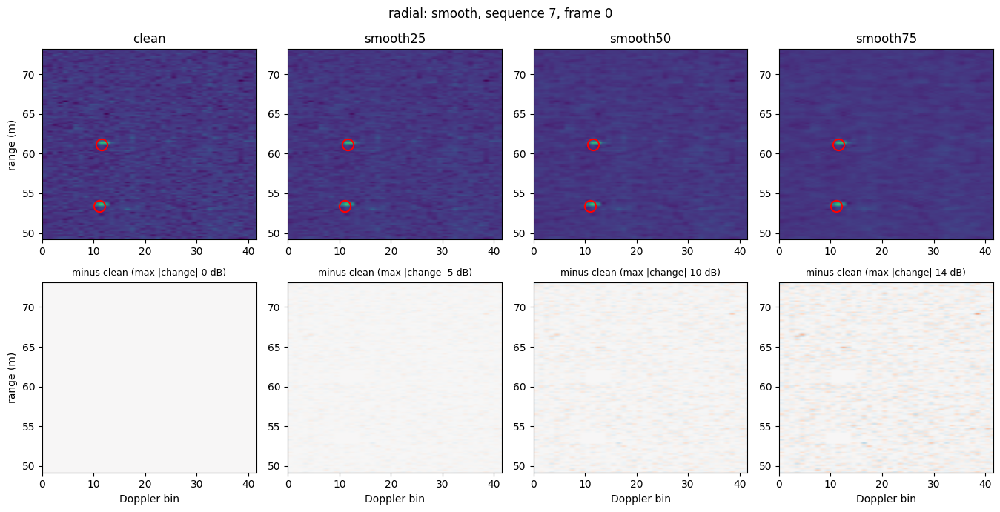

In [22]:
show_family("radial", "smooth", zoom=60)

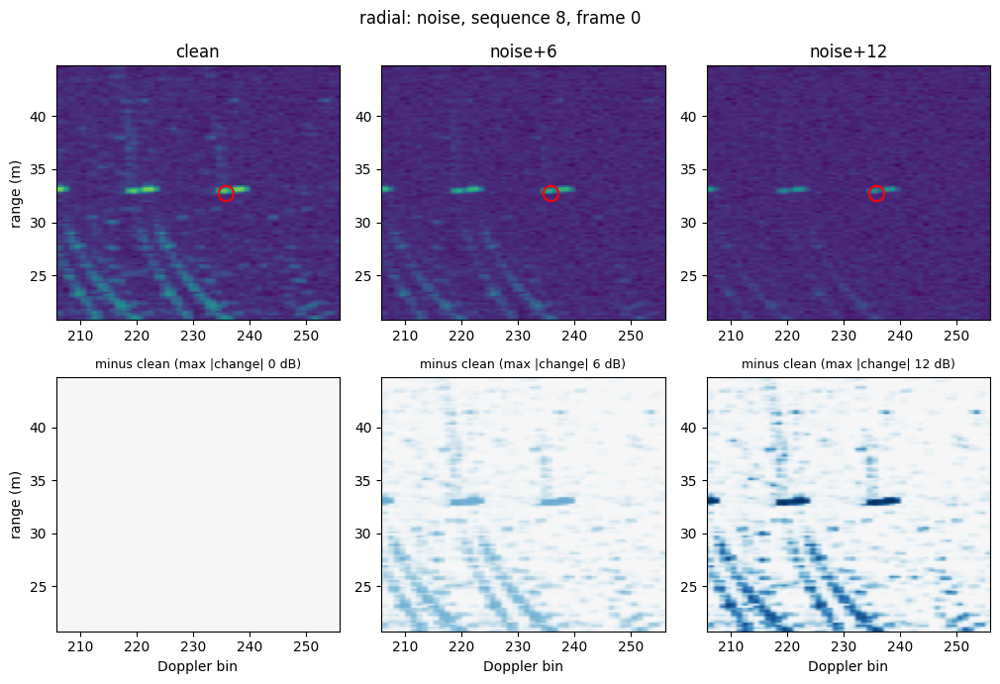

In [23]:
show_family("radial", "noise", zoom=60)

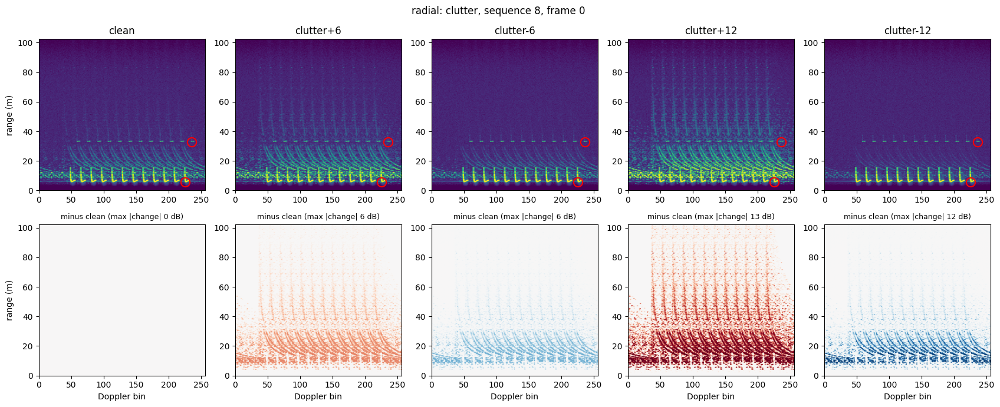

In [24]:
show_family("radial", "clutter")

### RADIal results (126 runs)

score    setting    gap  noise gap/noise  ordered families      pass
ap2      only     0.358  0.077       4.6  2/5 contrast,smooth  False
ap2      mix      0.048  0.026       1.9  0/5                  False
ap4      only     0.481  0.089       5.4  2/5 contrast,smooth  False
ap4      mix      0.035  0.018       1.9  0/5                  False
recall2  only     0.566  0.107       5.3  2/5 contrast,smooth  False
recall2  mix      0.034  0.020       1.7  0/5                  False


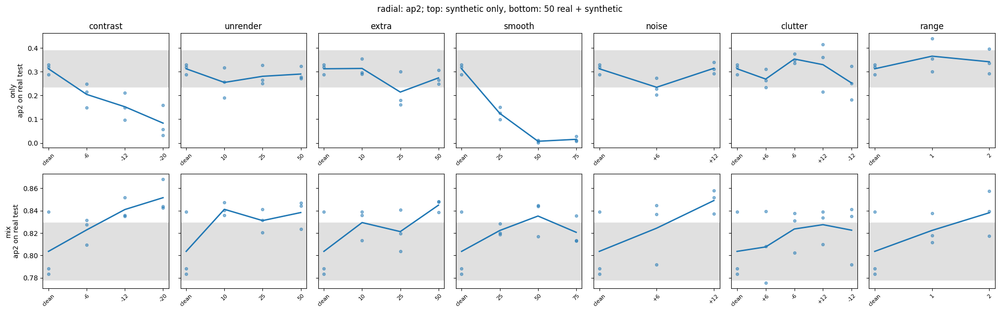

In [25]:
print_verdict("radial")
show_results("radial", "ap2")

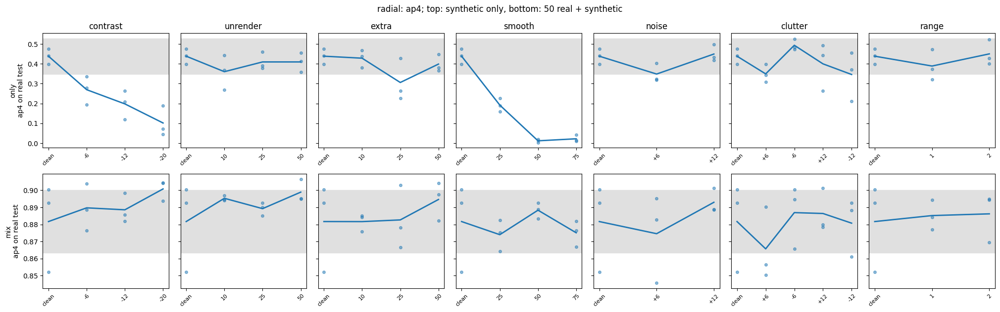

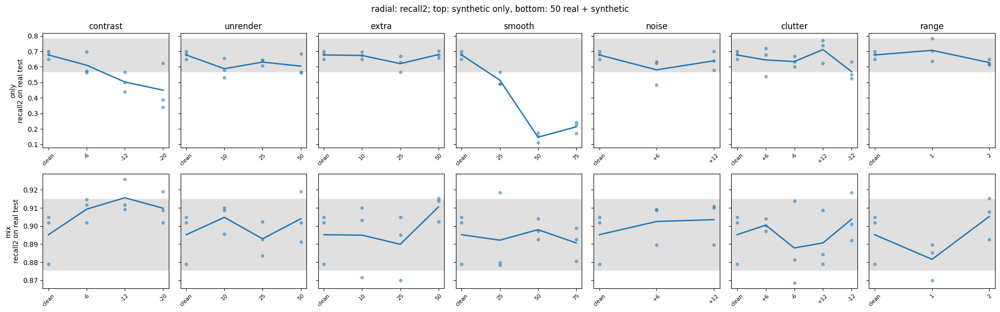

In [26]:
show_results("radial", "ap4")
show_results("radial", "recall2")

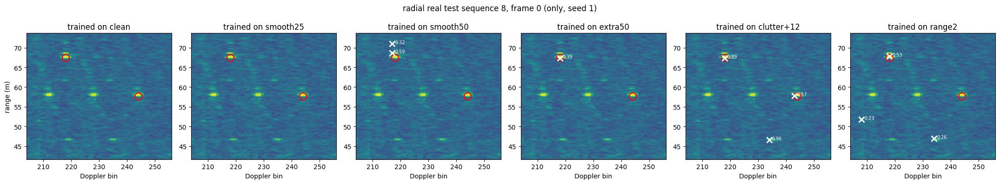

In [27]:
show_detections("radial", ["clean", "smooth25", "smooth50", "extra50", "clutter+12", "range2"], zoom=80)